# CAR-T: tumor control and activation tradeoffs

The review asks whether controlled engagement can preserve tumor killing while reducing inflammatory activation. This prototype asks **whether binding/exposure dynamics can account for that tradeoff, and which missing measurements could change the comparison**.

The published population reference is literature-derived; the extensions contain explicit reaction schemes and response assumptions. CD19/CD22 and FITC-folate remain separate architectures. No assay fit or independent biological confirmation is claimed. [Equation provenance](MODEL.md#equation-provenance) · [Rationale and evidence](README.md).

In [1]:
import os
from pathlib import Path
import numpy as np
from IPython.display import SVG, display
from cart_dynamics import reference
from cart_dynamics.study import run_study
from cart_dynamics.pkpd_study import run_study as run_pkpd

output = Path(os.environ.get("CAR_T_OUTPUT_DIR", "results"))
print("Published HDLM-2/CD123 reference: coexistence [effector, memory, tumor] in cells")
print(np.array2string(reference.coexistence_equilibria(), precision=3, suppress_small=True))
print("Table-derived lower tumor root is 1091.197; source text prints 1089 (0.20% difference).")

Matplotlib is building the font cache; this may take a moment.


Published HDLM-2/CD123 reference: coexistence [effector, memory, tumor] in cells
[[  15205.233  197518.706    1091.197]
 [  15205.203     263.366 1442519.914]]
Table-derived lower tumor root is 1091.197; source text prints 1089 (0.20% difference).


## Recognition and antigen escape

Four tumor phenotypes share one capacity and an explicitly accounted cell population. Compare recognition rules using identical starting populations and rates, then 64 paired parameter scenarios. Values below are simulated populations, not response rates.

Initial tumor: 1.000 million cells; horizon: 30 days
Recognition      Final tumor (million)   Minimum tumor (million)   Proxy AUC (a.u. days)
CD19                           12.2875                    0.5146                  0.8120
CD22                           12.9745                    0.5393                  0.8085
OR                              1.1082                    0.0721                  0.7352
AND                            22.1239                    1.0000                  1.1251
Independent-solver maximum absolute state difference: 4.335856298998131e-09
Sensitivity: OR has lower final burden than CD19 in 64 of 64 selected parameter scenarios.


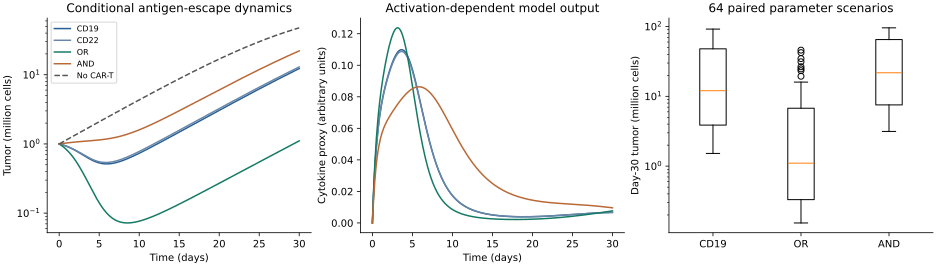

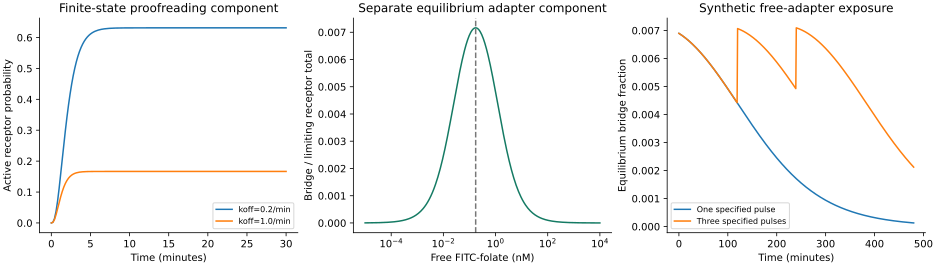

In [2]:
recognition = run_study(output, samples=64, seed=20261126)
print("Initial tumor: 1.000 million cells; horizon: 30 days")
print(f"{'Recognition':<14} {'Final tumor (million)':>23} {'Minimum tumor (million)':>25} {'Proxy AUC (a.u. days)':>23}")
for name, row in recognition["nominal"].items():
    print(f"{name.upper():<14} {row['final_tumor_million_cells']:23.4f} {row['minimum_tumor_million_cells']:25.4f} {row['cytokine_proxy_auc_arbitrary_unit_days']:23.4f}")
print("Independent-solver maximum absolute state difference:", recognition["numerical_checks"]["dop853_radau_max_absolute_difference"])
print("Sensitivity: OR has lower final burden than CD19 in", recognition["uncertainty"]["paired_or_below_cd19_count"], "of 64 selected parameter scenarios.")
display(SVG(filename=str(output / "cart_population.svg")))
display(SVG(filename=str(output / "cart_components.svg")))

## Controlled exposure: a modest PK/PD connection

The separate folate-receptor model couples adapter clearance and finite binding kinetics to CAR-T expansion, tumor killing and an inflammatory-activation proxy. Four schedules deliver equal concentration-equivalent input; follow-up includes washout. Sixteen paired scenarios vary unmeasured kinetics and potency at fixed published affinities. No clinical dose conversion is made.

Horizon: 14 days; active input: 0.7 nM concentration equivalents over 7 days
Schedule           Final tumor (million)   Peak proxy (a.u.)    Free AUC (nM days)
no_adapter                        7.6201              0.0000              0.000000
daily_bolus                       6.3259              0.0266              0.042079
split_bolus                       3.4767              0.1014              0.042079
ramped_bolus                      6.7077              0.0195              0.042079
continuous                        2.6375              0.1303              0.042079
Nominal nondominated schedules (final tumor / peak proxy): ['daily_bolus', 'split_bolus', 'ramped_bolus', 'continuous']
Lowest final tumor across 16 sensitivity scenarios: {'daily_bolus': 0, 'split_bolus': 1, 'ramped_bolus': 0, 'continuous': 15}
Source SHA-256: 273096ce3d50d1f660a59874b2a2035ee4b7bdef5411adf22f55c5c7ce38968d
Runtime including figures, seconds: 18.43


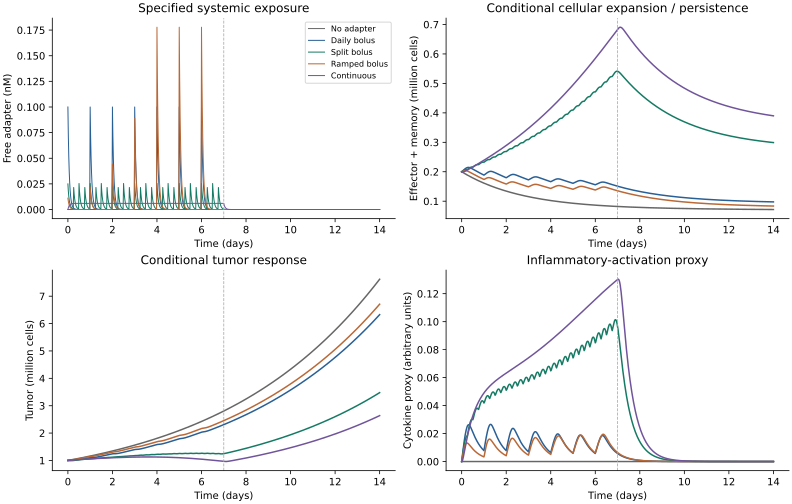

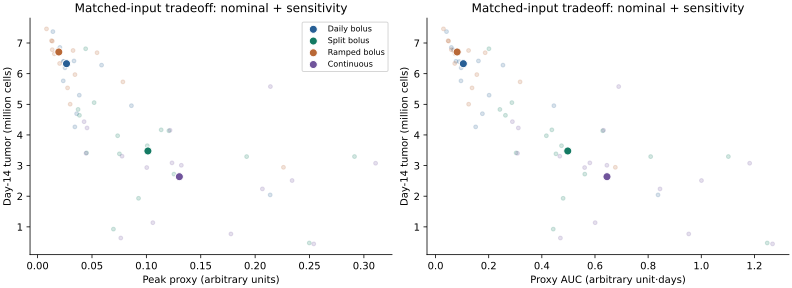

In [3]:
exposure = run_pkpd(output, samples=16, seed=20261126)
print("Horizon: 14 days; active input: 0.7 nM concentration equivalents over 7 days")
print(f"{'Schedule':<17} {'Final tumor (million)':>22} {'Peak proxy (a.u.)':>19} {'Free AUC (nM days)':>21}")
for name, row in exposure["nominal"].items():
    print(f"{name:<17} {row['final_tumor_million_cells']:22.4f} {row['peak_cytokine_proxy_arbitrary_units']:19.4f} {row['free_adapter_auc_nM_days']:21.6f}")
print("Nominal nondominated schedules (final tumor / peak proxy):", exposure["nominal_peak_proxy_frontier_active_protocols"])
print("Lowest final tumor across 16 sensitivity scenarios:", exposure["sensitivity"]["lowest_final_tumor_counts"])
print("Source SHA-256:", exposure["source_sha256"])
print("Runtime including figures, seconds:", round(recognition["end_to_end_seconds_including_figures"] + exposure["end_to_end_seconds_including_figures"], 2))
display(SVG(filename=str(output / "pkpd_trajectories.svg")))
display(SVG(filename=str(output / "pkpd_tradeoffs.svg")))

## Interpretation

Dual OR recognition suppresses more phenotypes in the nominal study, but double-negative escape drives regrowth. The adapter study shows a suppression/activation tradeoff, rather than reproducing the review's reported co-improvement. Changing unknown rates can alter schedule rankings at fixed affinities.

These are conditional consequences, not independent confirmation of the review. Experimental usefulness requires matched killing/cytokine observations, an identifiable fitted subset and withheld-condition predictions. A prediction failure would challenge the combined model and observation assumptions without establishing a unique missing mechanism.